In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import RegressorMixin
from sklearn.cluster import KMeans
from sklearn.model_selection import cross_val_score
from sklearn.utils import Bunch
from xgboost import XGBRegressor


# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)
    
def score_dataset(X, y, model=None):
    if model is None:
        model =  XGBRegressor()
    # Label encoding for categoricals
    for colname in X.select_dtypes(["category", "object"]):
        X[colname] = X[colname].astype(str).fillna("missing")
        X[colname], _ = X[colname].factorize()
    score = cross_val_score(
        model, X, y, cv=5, scoring="neg_mean_squared_log_error",
    )
    score = -1 * score.mean()
    score = np.sqrt(score)
    return score


# Prepare data
ames_data = pd.read_csv("../datasets/fe-course-data/ames.csv")

X = ames_data.copy()
y = X.pop("SalePrice")

In [2]:
# Creating a k-means clustering with the following parameters:
# - features: `LotArea`, `TotalBsmtSF`, `FirstFlrSF`, `SecondFlrSF`,`GrLivArea`
# - number of clusters: 10
# - iterations: 10

features = ['LotArea', 'TotalBsmtSF', 'FirstFlrSF', 'SecondFlrSF','GrLivArea']

# Standardize
X_scaled = X.loc[:, features]
X_scaled = (X_scaled - X_scaled.mean(axis=0)) / X_scaled.std(axis=0)

# Fit the KMeans model to X_scaled and create the cluster labels
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)
X["Cluster"] = kmeans.fit_predict(X_scaled)

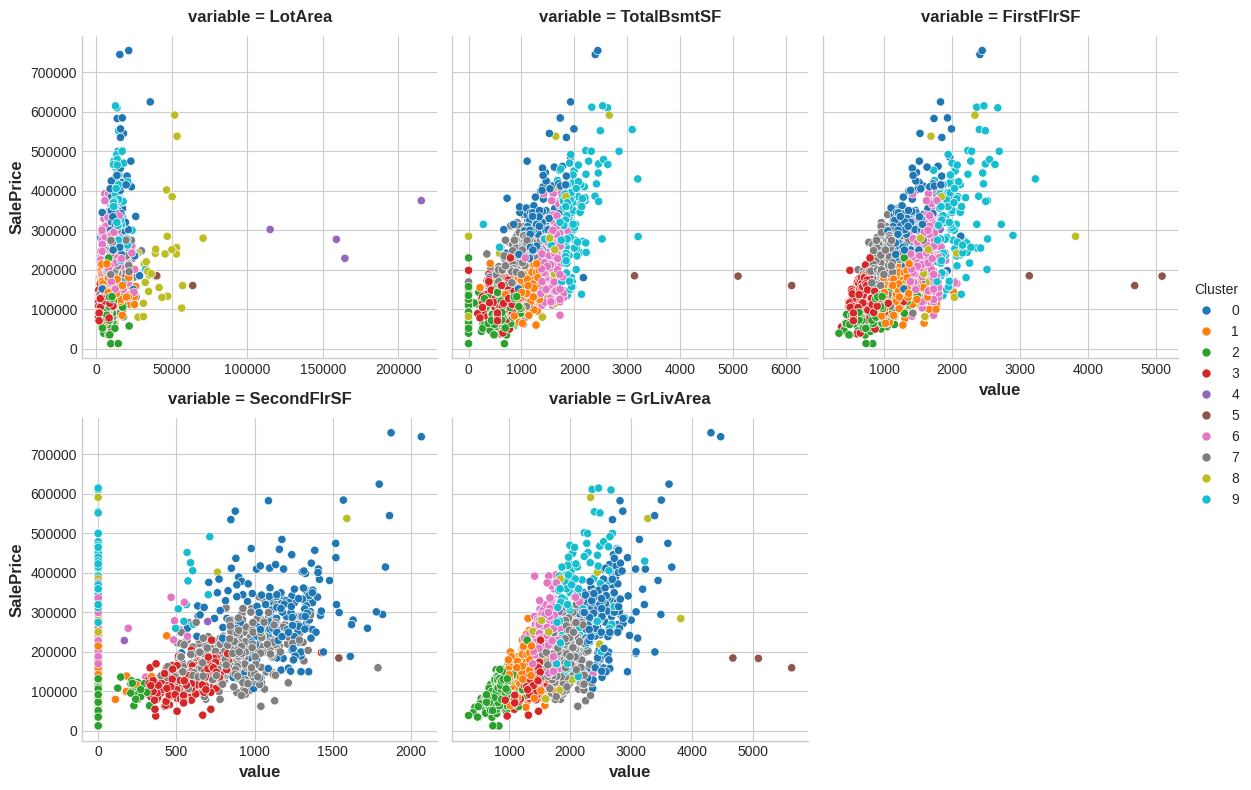

In [3]:
Xy = X.copy()
Xy["Cluster"] = Xy.Cluster.astype("category")
Xy["SalePrice"] = y
sns.relplot(
    x="value", y="SalePrice", hue="Cluster", col="variable",
    height=4, aspect=1, facet_kws={'sharex': False}, col_wrap=3,
    data=Xy.melt(
        value_vars=features, id_vars=["SalePrice", "Cluster"],
    ),
)

In [4]:
score_dataset(X, y) #0.1424377124868132

np.float64(0.14550799781618345)

In [5]:
kmeans = KMeans(n_clusters=10, n_init=10, random_state=0)

# Create cluster-distance features using `fit_transform`
X_cd = kmeans.fit_transform(X_scaled)

# Label features and join to dataset
X_cd = pd.DataFrame(X_cd, columns=[f"Centroid_{i}" for i in range(X_cd.shape[1])])
X = X.join(X_cd)

In [6]:
X

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,Centroid_0,Centroid_1,Centroid_2,Centroid_3,Centroid_4,Centroid_5,Centroid_6,Centroid_7,Centroid_8,Centroid_9
0,0,0,141.0,31770.0,0,0,0,0,0,0,...,4.134181,3.236678,3.977023,4.316398,16.792665,13.097627,2.870851,3.789935,1.604330,3.315926
1,0,1,80.0,11622.0,0,0,1,0,0,1,...,4.615628,1.075352,0.621685,1.885029,19.594509,15.785445,2.575580,2.745164,4.932333,4.508933
2,0,0,81.0,14267.0,0,0,0,0,0,0,...,3.707220,0.953832,2.157567,2.713650,19.030448,14.058973,0.975653,2.618381,3.927018,2.780135
3,0,0,93.0,11160.0,0,0,1,0,0,0,...,3.874506,3.792481,5.085077,5.236814,19.392116,11.373003,2.243512,4.444882,4.673607,0.508460
4,1,0,74.0,13830.0,0,0,0,0,0,1,...,2.651716,2.070336,2.337714,1.306043,19.225117,14.749591,2.660527,0.733775,4.390193,4.103626
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,6,0,37.0,7937.0,0,0,0,0,0,2,...,4.385914,0.632596,0.786743,1.872145,19.983709,15.515254,2.158623,2.615104,5.110022,4.128159
2926,0,0,0.0,8885.0,0,0,0,3,0,1,...,4.637266,1.039369,0.404809,1.791325,19.937172,15.897940,2.586619,2.737873,5.212695,4.548788
2927,4,0,62.0,10441.0,0,0,1,0,0,1,...,4.453410,0.806070,0.628910,1.845923,19.701445,15.610602,2.335405,2.629335,4.917455,4.284502
2928,0,0,77.0,10010.0,0,0,1,0,0,1,...,3.645022,0.954872,2.256738,2.748809,19.548612,14.012415,0.623647,2.635832,4.385419,2.586722


In [7]:
score_dataset(X, y) # 0.13822238726596872

np.float64(0.13682110331039601)